<a href="https://colab.research.google.com/github/aliradameli/kwave-Breast-Tissue-Modeling/blob/main/Tissue_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.animation import FuncAnimation
import cv2 as cv
from kwave.kgrid import kWaveGrid

from kwave.kmedium import kWaveMedium
from kwave.ksource import kSource
from kwave.ksensor import kSensor
from kwave.kspaceFirstOrder2D import kspaceFirstOrder2D 
from decimal import Decimal

import warnings
import zlib
from scipy import ndimage
from scipy.spatial import cKDTree
from scipy.stats import truncnorm

from grid_utils import GridUnits

plt.style.use('default')
 

In [ ]:
base_rndseed = 40
np.random.seed(base_rndseed)

# define the computational grid
dx = 10e-6 # grid point spacing in the x and y direction [m]
dy = 10e-6 # grid point spacing in the x and y direction [m]
Nx = 4*1024  # number of grid points in the x direction
Ny = 4*1024   # number of grd points in the y direction
grid = kWaveGrid([Nx, Ny], [dx, dy])
X , Y = np.meshgrid(grid.x_vec, grid.y_vec , indexing='ij')
grid.makeTime(c=1540, t_end=3e-5, cfl=0.5)


(array([[0.00000000e+00, 3.24675325e-09, 6.49350649e-09, ...,
         2.99935065e-05, 2.99967532e-05, 3.00000000e-05]], shape=(1, 9241)),
 np.float64(3.246753246753247e-09))

In [ ]:
"""Beacon generator: draws high-SOS / high-density reference structures on top of
an existing (sos_map, rho_map) pair. Moved out of BreastMap unchanged in logic.
More beacon shapes can be added here later.
"""


class BeaconMap(GridUnits):
    def __init__(self, sos_map, rho_map, dx, dy,
                 numbers_of_sensors=32, sensor_length=30, pitch=2):
        self.sos_map = np.array(sos_map, dtype=float, copy=True)
        self.rho_map = np.array(rho_map, dtype=float, copy=True)
        self.Nx, self.Ny = self.sos_map.shape
        self.dx = dx
        self.dy = dy
        self.numbers_of_sensors = numbers_of_sensors
        self.sensor_length = sensor_length
        self.pitch = pitch
        self.one_beacon_depth = int(3 * self.Ny / 4)

    def addBeacon(self, beacon_width=32, high_sos_val=2000, high_rho_val=2000):
        """Staircase of square beacons (width given in microns)."""
        beacon_width = self.microns2pixels(beacon_width)
        beacon_number = self.Nx // beacon_width
        beacon_thickness = self.Ny // beacon_number
        for i in range(0, beacon_number):
            self.sos_map[i * beacon_width:(i + 1) * beacon_width,
                         i * beacon_thickness:(i + 1) * beacon_thickness] = high_sos_val
            self.rho_map[i * beacon_width:(i + 1) * beacon_width,
                         i * beacon_thickness:(i + 1) * beacon_thickness] = high_rho_val
        return self

    def addRectangularBeacon(self, high_sos_val=2000, high_rho_val=2000):
        pattern_length = self.pitch + self.sensor_length
        imaging_area_length = pattern_length * self.numbers_of_sensors
        x0 = (self.Nx - imaging_area_length) / 2
        Ny = self.Ny
        # cv.rectangle points are (col, row) = (depth index, lateral index) for (Nx, Ny) arrays
        for m, v in ((self.sos_map, high_sos_val), (self.rho_map, high_rho_val)):
            cv.rectangle(m, (int(Ny / 4 / 2), int(x0)),
                         (int(Ny / 2 / 2), int(x0 + imaging_area_length / 3)), v, -1)
            cv.rectangle(m, (int(Ny / 2 / 2), int(x0 + imaging_area_length / 3)),
                         (int(3 * Ny / 4 / 2), int(x0 + 2 * imaging_area_length / 3)), v, -1)
            cv.rectangle(m, (int(3 * Ny / 4 / 2), int(x0 + 2 * imaging_area_length / 3)),
                         (int(Ny / 2), int(x0 + imaging_area_length)), v, -1)
        return self

    def addFlatBeacon(self, depth, thickness, high_sos_val=2000, high_rho_val=2000):
        self.sos_map[:, depth - thickness:depth + thickness] = high_sos_val
        self.rho_map[:, depth - thickness:depth + thickness] = high_rho_val
        return self

    def addOnePointBeacon(self, frequency, high_sos_val=2000, high_rho_val=2000):
        """frequency in MHz; beacon size = lambda/2 (lambda computed with c = 1500 m/s)."""
        depth = self.one_beacon_depth
        wavelength = int(self.microns2pixels(1500 / frequency))
        width = wavelength // 2
        thickness = width
        for m, v in ((self.sos_map, high_sos_val), (self.rho_map, high_rho_val)):
            cv.rectangle(m, (depth, int(self.Nx / 2 - width / 2)),
                         (depth + thickness, int(width / 2 + self.Nx / 2)), v, -1)
        return self

    def addRectangleAt(self, depth, distance_from_right, length, width,
                       high_sos_val=2000, high_rho_val=2000):
        """Rectangular beacon centered at a point given in meters.

        depth               : distance of the center from the top surface (axis 1, dy)  [m]
        distance_from_right : distance of the center from the right edge (axis 0, dx)   [m]
                              (x grows to the right, i.e. the right edge is x = Nx*dx)
        length              : lateral (left-right) extent  [m]
        width               : axial (depth) extent         [m]
        Parts outside the map are clipped (a warning is issued); the rectangle is at
        least one pixel in each direction.
        """
        cx = self.Nx * self.dx - distance_from_right     # center, meters from the left edge
        cz = depth

        def span(center, size, step, n):
            lo = int(round((center - size / 2) / step))
            hi = int(round((center + size / 2) / step))
            if hi <= lo:                                  # keep at least 1 pixel
                hi = lo + 1
            return lo, hi, max(lo, 0), min(hi, n)

        x_lo, x_hi, x0, x1 = span(cx, length, self.dx, self.Nx)
        z_lo, z_hi, z0, z1 = span(cz, width, self.dy, self.Ny)
        if x1 <= x0 or z1 <= z0:
            warnings.warn("Rectangle lies completely outside the map; nothing drawn.")
            return self
        if (x0, x1, z0, z1) != (x_lo, x_hi, z_lo, z_hi):
            warnings.warn("Rectangle partly outside the map; it was clipped.")
        self.sos_map[x0:x1, z0:z1] = high_sos_val
        self.rho_map[x0:x1, z0:z1] = high_rho_val
        return self

    def get_sos(self):
        return self.sos_map.copy()

    def get_rho(self):
        return self.rho_map.copy()

In [52]:
"""2-D numerical breast phantom (speed-of-sound + density maps), depth 0-8 cm.

Maps have shape (Nx, Ny): axis 0 = lateral (dx), axis 1 = depth (dy); depth = Ny*dy [m].

Reference tags used in comments (all taken from the "Comprehensive Acoustic Reference for
2D Numerical Breast Phantom Modeling (0-8 cm)" document, abbreviated REF §n, and the papers it cites):
  IT'IS   = Hasgall et al. (2022), IT'IS database v4.1
  Duck90  = Duck (1990);  Szabo14 = Szabo (2014)
  Li09 / Li21 = Li et al. (2009) / Li, Villa, Park, Anastasio (2021)
  Pawlowska22 = Pawlowska, Zolek, Litniewski (2022)   Larson21 = Larson et al. (2021)
  Klock16, Keijzer18, Lou17, Moran95, Opielinski18, Ruby19, Boehm19, Dunn74, OBrien02,
  Woodard86, Chivers78, Klimonda19, Machado19 -> see the bibliography of the reference document.
Where the reference gives only a range (no SD) the SD used here is (max-min)/6  -> marked (*).
Where a value is a modelling choice of this code (not in the reference) it is marked [ASSUMPTION].

Usage:
    bm = BreastMap(Nx=400, Ny=400, dx=2e-4, dy=2e-4, rndseed=1, birads='C')
    bm.disable('ribs', 'pleura_lung')          # entities can be removed ...
    bm.enable('costal_cartilage')              # ... or added
    bm.build()
    sos, rho = bm.get_sos(), bm.get_rho()
Old chain style (bm.addGel().addEpidermis()...) still works; each add* is a no-op when its
entity is disabled. Use build() for the correct order.
"""

MAX_DEPTH_M = 0.08  # REF §1: phantom extends to 8 cm

# ----------------------------------------------------------------------------------------------
# Acoustic properties: (mean, sd, min, max). c in m/s, rho in kg/m^3.  Source: REF §2 master table
# ----------------------------------------------------------------------------------------------
ACOUSTIC_PROPS = {
    # Coupling medium: water/gel. IT'IS; Li21; Lou17. c range = temperature dependent 1482-1525.
    # (original code used propylene glycol 1467-1541 / 1036-1040; replaced by REF §2 values)
    'water_gel':   {'c': (1500, 8, 1482, 1525),        'rho': (997, 1.5, 994, 1000)},          # (*)
    # Epidermis: Moran95; Agache & Humbert; c 1532-1736, rho 1110-1190 (nominal 1150)
    'epidermis':   {'c': (1645, 34, 1532, 1736),       'rho': (1150, 13, 1110, 1190)},          # (*)
    # Dermis: Moran95; IT'IS; Raju & Srinivasan. rho 1109 +/- 14 (IT'IS)
    'dermis':      {'c': (1595, 19, 1569, 1681),       'rho': (1109, 14, 1090, 1130)},          # (*) c
    # Fat (subcutaneous + retromammary): IT'IS; Li09/Li21 (ex vivo / room T); Pawlowska22
    'fat':         {'c': (1440.2, 20.9, 1412, 1485),   'rho': (911, 53, 812, 961)},             # Li21 TN(...)
    # Fibroglandular: Li21 TN(1540,15,1517,1567), rho TN(1041,45.3,990,1092); Keijzer18; Klock16
    'gland':       {'c': (1540, 15, 1517, 1567),       'rho': (1041, 45.3, 990, 1092)},
    # Lactiferous ducts: Duck90; Szabo14; Klock16 (bulk 1545, ductal tree up to 1586, range 1530-1612)
    'duct':        {'c': (1545, 15, 1530, 1612),       'rho': (1030, 7, 1020, 1045)},           # (*) rho
    # Cooper's ligaments. REF §3.3(1): fine grid (<=0.25 mm) -> pure collagen 1650-1750 (Pawlowska22);
    # coarse grid -> volume-averaged 1457 +/- 18.5 (Li21; Opielinski18). rho 1142 +/- 45 (IT'IS), 1170 (Pawlowska22)
    'cooper_fine':   {'c': (1750, 25, 1650, 1750),     'rho': (1142, 45, 1027, 1174)},
    'cooper_coarse': {'c': (1457, 18.5, 1422, 1750),   'rho': (1142, 45, 1027, 1174)},
    # Blood: IT'IS; Chivers78; Lou17  (lumen). Vessel wall: IT'IS blood-vessel wall.
    'blood':       {'c': (1578, 11, 1560, 1590),       'rho': (1050, 19, 1025, 1069)},
    'vessel_wall': {'c': (1584, 15, 1555, 1610),       'rho': (1102, 53, 1049, 1155)},          # (*) c
    # Lesions (REF §2 + §3.3(2): use rho 1055-1070 for solid tumours, NOT Li21's fat-mixed 945)
    'idc':         {'c': (1548, 17, 1509, 1580),       'rho': (1062, 5, 1055, 1070)},           # Li09/21; Boehm19; Pawlowska22
    'dcis':        {'c': (1535, 15, 1510, 1565),       'rho': (1055, 8, 1035, 1070)},           # Li09; Ruby19
    'fibroadenoma': {'c': (1513, 27, 1486, 1540),      'rho': (1045, 9, 1020, 1065)},           # Li09; Ruby19
    'cyst':        {'c': (1510, 7, 1495, 1530),        'rho': (1020, 3, 1010, 1025)},           # IT'IS plasma/serum; REF §3.4
    # Chest wall
    'pect_parallel':      {'c': (1590, 6, 1580, 1600), 'rho': (1090, 55, 1041, 1178)},         # IT'IS; Woodard86 (along fibres)
    'pect_perpendicular': {'c': (1560, 6, 1550, 1570), 'rho': (1090, 55, 1041, 1178)},         # across fibres
    'intercostal': {'c': (1580, 10, 1550, 1600),       'rho': (1090, 55, 1041, 1178)},          # IT'IS skeletal muscle
    'cartilage':   {'c': (1680, 30, 1580, 1750),       'rho': (1100, 40, 1060, 1150)},          # IT'IS (1665/1696 quoted)
    'rib_cortex':  {'c': (3300, 150, 2800, 3700),      'rho': (1908, 166, 1740, 2100)},         # IT'IS; REF quotes 3100/3500 -> midpoint
    'rib_cancellous': {'c': (2000, 150, 1430, 2200),   'rho': (1178, 197, 930, 1375)},          # IT'IS
    'rib_marrow':  {'c': (1450, 10, 1430, 1470),       'rho': (980, 15, 930, 1000)},            # IT'IS yellow marrow
    # Inflated lung: Dunn74; OBrien02 (c 343-965, 400-658 at 1-2 MHz; rho 260-400)
    'lung':        {'c': (500, 60, 400, 658),          'rho': (330, 40, 260, 400)},
}

# In-vivo (37 C) overrides, REF §3.3(3): Li21 in-vivo USCT fat 1422+/-9, gland 1487+/-21.
# NOTE the reference asks for internal consistency: other tissues keep their table values.
IN_VIVO_OVERRIDE = {
    'fat':   {'c': (1422, 9, 1412, 1485)},
    'gland': {'c': (1487, 21, 1470, 1567)},
}

# Constant inclusions. REF §3.2: calcium hydroxyapatite c=3200 m/s, rho=2800 kg/m^3
MICROCALC_C, MICROCALC_RHO = 3200.0, 2800.0
# REF §3.1: spiculated rim voxels use tumour/collagen properties c~1560, rho~1070
HALO_C, HALO_RHO = 1560.0, 1070.0

# Macro-scale correlated fields, REF §3.4 (Li21): correlation lengths in meters
CORR_LEN = {'fat_c': 28.8e-3, 'fat_rho': 18.2e-3, 'gland_c': 30.4e-3, 'gland_rho': 20.8e-3}

# BI-RADS adipose fraction in the parenchymal zone, REF §3.5
BIRADS_KFAT = {'A': 0.95, 'B': 0.85, 'C': 0.66, 'D': 0.40}

# =============================================================================================
# LESION STATISTICS (literature search, Nov 2026). Tags:
#  Littrup21 = Littrup PJ, Duric N, Sak M, et al. J Breast Imaging 2021, doi:10.1093/jbi/wbab032
#              (UST, 206 women, 78 cancers / 105 fibroadenomas / 91 cysts). NOTE: your reference
#              doc cites this paper as "Larson et al. 2021" -- the author list looks wrong.
#  Duric21   = Duric N, Sak M, Littrup PJ. J Clin Med 2021;10(23):5615, doi:10.3390/jcm10235615
#  Rauch13   = Rauch GM et al. Breast Cancer Res Treat 2013 (MD Anderson, 1187 pure DCIS; PMC3982796)
#  Elverici15= Elverici E et al. Diagn Interv Radiol 2015 (186 nonpalpable BI-RADS 4 lesions; PMC4463260)
#  Stavros99 = "Benign versus malignant solid breast masses: US differentiation", Radiology 1999;
#              213(3):889-94 (162 solid masses; W/AP > 1.4 -> 89% benign)
#  Clauser17 = Clauser P et al. Breast Care 2017;12(4):238-242 (349 fibroadenomas, PMC5649257)
#  Dogan17   = Dogan E et al. Med J Mugla Sitki Kocman Univ 2017;4(3):13-18 (39 fibroadenomas)
#  Berg10    = Berg WA et al. Radiol Clin North Am 2010 (cystic masses, ACRIN 6666)
#  Radiology16 = Radiology 2016;283(1):49-58 (screening mammography cancers; PMC5375631 Table 4)
#  CEUS-IDC  = PMC4527309 (106 invasive ductal cancers, CEUS width/depth)
#  TSD130    = PMC10965701 Table 2 (130 cancers; sonographic tumor-to-skin distance, nipple distance)
# =============================================================================================

# Relative frequency of lesion types. Cohort counts from Littrup21 (78 cancers : 105 FA : 91 cysts =
# 0.285 : 0.383 : 0.332). That is a trial population, not general prevalence. The split of the cancer
# share into IDC 80% / DCIS 20% is an [ASSUMPTION].
TUMOR_WEIGHTS = {'idc': 0.228, 'dcis': 0.057, 'fibroadenoma': 0.383, 'cyst': 0.332}

# Long-axis (lateral) diameter, truncated log-normal: (median mm, sigma of ln, min mm, max mm).
#  idc : median 13.0 / mean 15.9 mm (Radiology16 invasive cancers) -> sigma = sqrt(2 ln(mean/median)) = 0.634;
#        consistent with Littrup21 (mean 13 mm, 52/78 < 15 mm) and TSD130 (US size 13 +/- 7.8 mm).
#  dcis: ultrasound size mean ~17 mm, SD ~14.5 mm (Rauch13: 16 +/- 14 ER+, 23 +/- 17 ER-) -> lognormal moment fit.
#  fibroadenoma: Clauser17 (<=10 mm 52%, 11-20 mm 40%, >=21 mm 7.6%) + Littrup21 mean 11 mm -> median 10, sigma 0.485;
#        Dogan17 long diameter 15.8 +/- 7.9 mm (6-50 mm, biopsied lesions).
#  cyst: Littrup21 mean 10 mm, 88% < 15 mm -> median 9.2, sigma 0.40; Berg10: 2-3 mm to 5-6 cm possible.
# Upper clip 30 mm [ASSUMPTION, so the lesion fits the 3-6 cm breast corpus; REF §4 suggested 1.5-20 mm, but
# ~25% of invasive cancers exceed 20 mm in the literature]; lower clip 1.5 mm (REF §4).
LESION_SIZE_MM = {'idc': (13.0, 0.634, 1.5, 30.0), 'dcis': (12.9, 0.739, 1.5, 30.0),
                  'fibroadenoma': (10.0, 0.485, 4.0, 30.0), 'cyst': (9.2, 0.40, 2.0, 30.0)}

# Shape class probabilities.
#  idc  : Elverici15 malignant lesions: oval 24, round 13, irregular 35 of 72.
#  dcis : Rauch13 sonographic mass shape: irregular 116, oval 45, round 9 of 170.
#  fibroadenoma: Clauser17 US shape (n=330): oval 69.7%, lobulated 17.6%, round 12.7%.
#  cyst : tense cysts round, relaxed cysts flat/oval (Berg10) -> 50/50 [ASSUMPTION].
SHAPE_PROBS = {'idc': {'oval': 0.333, 'round': 0.181, 'irregular': 0.486},
               'dcis': {'oval': 0.265, 'round': 0.053, 'irregular': 0.682},
               'fibroadenoma': {'oval': 0.697, 'round': 0.127, 'lobulated': 0.176},
               'cyst': {'oval': 0.5, 'round': 0.5}}

# Depth/width ratio D/W (AP / lateral), (mean, sd, min, max).
#  malignant: Elverici15 malignant mean vertical/horizontal = 7.2/10.9 = 0.66 (small BI-RADS 4 lesions);
#             CEUS-IDC median depth/width = 19.5/23.5 = 0.83 (larger, node-staged cancers) -> mean 0.75;
#             sd 0.15 and the 0.45-1.3 bounds are [ASSUMPTION]. Gives ~60% with W/AP < 1.4 ("not parallel",
#             Stavros99), cf. 46-55% in Elverici15.
#  fibroadenoma (oval/lobulated): Dogan17 long/short diameter ratio 1.98 +/- 0.41 (1.3-3.0), 97% parallel;
#             Stavros99: wider-than-tall in ~99% of benign-pattern masses.
#  round shape (any type): D/W near 1  [ASSUMPTION].  relaxed oval cyst: 0.6 +/- 0.12 [ASSUMPTION].
DW_MALIGNANT = (0.75, 0.15, 0.45, 1.3)
DW_FIBROADENOMA_AR = (1.98, 0.41, 1.3, 3.0)     # long/short -> D/W = 1/AR
DW_ROUND = (0.93, 0.05, 0.85, 1.0)
DW_CYST_OVAL = (0.6, 0.12, 0.4, 0.85)

# Where a lesion sits: (at FGI, inside gland, inside fat). Littrup21 (UST):
#   cancer 74/78 = 95% / 0% / 5%; fibroadenoma 66/105 = 63% / 35% / 2%; cyst 33/91 = 36% / 64% / 0%.
# (Duric21, quoting an earlier cohort: cancers 93%, FA 69%, cysts 40% at the FGI.)
# DCIS is assumed to follow the cancer row [ASSUMPTION].
# "At FGI" (Littrup21: partially surrounded by both fat and gland) = |signed distance of centre to the
# gland boundary| <= mean lesion radius.
PLACEMENT = {'idc': (0.95, 0.0, 0.05), 'dcis': (0.95, 0.0, 0.05),
             'fibroadenoma': (0.63, 0.35, 0.02), 'cyst': (0.36, 0.64, 0.0)}

# Distance priors (gamma distributions matched to mean +/- SD, TSD130 Table 2, n=130):
#  tumour-to-skin distance (skin -> nearest tumour margin): 8.6 +/- 4.4 mm (here: from the dermis bottom)
#  tumour-to-nipple distance: 41.1 +/- 30 mm. This is a 3-D distance; used as an in-plane lateral offset from
#  the nipple axis, an [ASSUMPTION] (in-plane offset <= 3-D distance).
TUMOR_TO_SKIN_MM = (8.6, 4.4)
TUMOR_TO_NIPPLE_MM = (41.1, 30.0)

# DCIS calcification distribution (Rauch13, mammography): cluster/group 56-57%; segmental 22%;
# regional 14-18%; linear 3-6%; diffuse 1%. Clustered -> compact group, otherwise spread over the lesion.
CALC_CLUSTER_PROB = 0.57

DEFAULT_ENTITIES = {
    'gel': True, 'epidermis': True, 'dermis': True,
    'fibroglandular': True, 'cooper_ligaments': True, 'ducts': True, 'vessels': True,
    'retromammary_fascia': True, 'pectoralis': True, 'muscle_striations': True,
    'intercostal_muscle': True, 'ribs': True,
    'costal_cartilage': False,   # True -> ribs drawn as costal cartilage (medial/sternal scan)
    'pleura_lung': True,
    'tumor_idc': True, 'tumor_dcis': True, 'tumor_fibroadenoma': True, 'tumor_cyst': True,
    'peritumoral_halo': True, 'microcalcifications': True,
    'lesion_distance_priors': True,   # weight lesion centres by tumour-to-skin / nipple distance priors
    'macro_heterogeneity': True, 'speckle': True,
}

LABELS = {'gel': 1, 'epidermis': 2, 'dermis': 3, 'fat': 4, 'fibroglandular': 5, 'cooper': 6,
          'duct': 7, 'vessel_wall': 8, 'blood': 9, 'idc': 10, 'dcis': 11, 'fibroadenoma': 12,
          'cyst': 13, 'halo': 14, 'microcalc': 15, 'fascia': 16, 'pectoralis': 17,
          'intercostal': 18, 'rib_cortex': 19, 'rib_core': 20, 'cartilage': 21, 'lung': 22}
TUMOR_LABELS = [LABELS[k] for k in ('idc', 'dcis', 'fibroadenoma', 'cyst')]


class BreastMap(GridUnits):
    def __init__(self, Nx, Ny, dx, dy, rndseed, max_num_tumors=3, entities=None,
                 birads='C', physiological_state='ex_vivo', center_frequency=5e6,
                 muscle_fiber_orientation='parallel', rib_core='cancellous'):
        """
        Nx, Ny, dx, dy : grid size and pixel size [m]; depth = Ny*dy must be <= 8 cm
        max_num_tumors : 1..max lesions are drawn (0 = none)
        entities       : dict of flags overriding DEFAULT_ENTITIES
        birads         : 'A'|'B'|'C'|'D' -> adipose fraction of the parenchymal zone (REF §3.5)
        physiological_state : 'ex_vivo' (22 C table values) | 'in_vivo' (37 C fat/gland, Li21)
        center_frequency : [Hz] only used to set the sub-wavelength scatterer density (speckle)
        muscle_fiber_orientation : 'parallel'|'perpendicular' (scan plane vs fibres; REF §2 pectoralis)
        rib_core       : 'cancellous' | 'marrow'
        """
        self.Nx, self.Ny, self.dx, self.dy = Nx, Ny, dx, dy
        self.rndseed = rndseed
        self.max_num_tumors = max_num_tumors
        self.depth = Ny * dy
        if self.depth > MAX_DEPTH_M + 1e-9:
            warnings.warn(f"Depth {self.depth*100:.1f} cm > 8 cm: anatomy is only defined to 8 cm; "
                          "everything below the chest wall is filled with lung/fat.")
        if birads not in BIRADS_KFAT:
            raise ValueError(f"birads must be one of {list(BIRADS_KFAT)}")
        if physiological_state not in ('ex_vivo', 'in_vivo'):
            raise ValueError("physiological_state must be 'ex_vivo' or 'in_vivo'")
        if muscle_fiber_orientation not in ('parallel', 'perpendicular'):
            raise ValueError("muscle_fiber_orientation must be 'parallel' or 'perpendicular'")
        if rib_core not in ('cancellous', 'marrow'):
            raise ValueError("rib_core must be 'cancellous' or 'marrow'")
        self.birads, self.state = birads, physiological_state
        self.center_frequency = center_frequency
        self.fiber_orientation, self.rib_core = muscle_fiber_orientation, rib_core

        self.entities = dict(DEFAULT_ENTITIES)
        if entities:
            self.set_entities(**entities)

        self.xx = np.arange(Nx) * dx          # lateral coordinates [m]
        self.zz = np.arange(Ny) * dy          # depth coordinates [m]
        self._reset()

    # ------------------------------------------------------------------ entity switches
    def set_entities(self, **flags):
        for k, v in flags.items():
            if k not in self.entities:
                raise KeyError(f"Unknown entity '{k}'. Available: {sorted(self.entities)}")
            self.entities[k] = bool(v)
        self._layout = None
        return self

    def enable(self, *names):
        return self.set_entities(**{n: True for n in names})

    def disable(self, *names):
        return self.set_entities(**{n: False for n in names})

    # ------------------------------------------------------------------ internals
    def _reset(self):
        self.sos_map = np.zeros((self.Nx, self.Ny))
        self.rho_map = np.zeros((self.Nx, self.Ny))
        self.label_map = np.zeros((self.Nx, self.Ny), dtype=np.int8)
        self.speckle_mask = np.zeros((self.Nx, self.Ny), dtype=bool)
        self.gland_mask = np.zeros((self.Nx, self.Ny), dtype=bool)
        self.lesions = []
        self.there_is_a_tumor = False
        self.gel_thickness = self.epi_thickness = self.total_skin_thickness = 0  # pixels
        self._layout = None

    def _rng(self, key):
        """Independent generator per entity -> toggling one entity doesn't change the others."""
        return np.random.default_rng([self.rndseed, zlib.crc32(key.encode())])

    def _spec(self, name, which):
        if self.state == 'in_vivo' and name in IN_VIVO_OVERRIDE and which in IN_VIVO_OVERRIDE[name]:
            return IN_VIVO_OVERRIDE[name][which]
        return ACOUSTIC_PROPS[name][which]

    @staticmethod
    def _tn(rng, spec, size=None):
        mean, sd, lo, hi = spec
        return truncnorm.rvs((lo - mean) / sd, (hi - mean) / sd, loc=mean, scale=sd,
                             size=size, random_state=rng)

    def _sample(self, name, rng):
        return float(self._tn(rng, self._spec(name, 'c'))), float(self._tn(rng, self._spec(name, 'rho')))

    def _paint(self, mask, c, rho, label, speckle=True):
        if isinstance(c, np.ndarray) and c.shape == mask.shape:
            c = c[mask]
        if isinstance(rho, np.ndarray) and rho.shape == mask.shape:
            rho = rho[mask]
        self.sos_map[mask] = c
        self.rho_map[mask] = rho
        self.label_map[mask] = LABELS[label]
        self.speckle_mask[mask] = speckle

    def _rows_mask(self, r0, r1):
        m = np.zeros((self.Nx, self.Ny), dtype=bool)
        m[:, max(0, r0):max(0, r1)] = True
        return m

    def _smooth2d(self, noise, sx, sz=None):
        """Gaussian smoothing with std sx (lateral) / sz (depth) in meters, via FFT (fast for big kernels)."""
        sz = sx if sz is None else sz
        F = ndimage.fourier_gaussian(np.fft.fft2(noise), sigma=(sx / self.dx, sz / self.dy))
        return np.fft.ifft2(F).real

    def _wavy(self, key, z0, amp, ell):
        """Smooth lateral undulation of a boundary depth (array over x)."""
        f = ndimage.gaussian_filter1d(self._rng('wavy_' + key).standard_normal(self.Nx),
                                      max(1.0, ell / self.dx), mode='wrap')
        return z0 + amp * f / (f.std() + 1e-12)

    def _macro_field(self, key, tissue, which):
        """Spatially correlated truncated-normal field (Li21, REF §3.4); constant if disabled.
        Truncation is done by clipping [ASSUMPTION: kernel std = correlation length]."""
        mean, sd, lo, hi = self._spec(tissue, which)
        if not self.entities['macro_heterogeneity']:
            return np.full((self.Nx, self.Ny), mean)
        rng = self._rng('macro_' + key)
        f = self._smooth2d(rng.standard_normal((self.Nx, self.Ny)), CORR_LEN[key])
        f = (f - f.mean()) / (f.std() + 1e-12)
        return np.clip(mean + sd * f, lo, hi)

    def _ellipse_frame(self, cx, cz, a, b, theta, reach):
        i0, i1 = max(0, int((cx - reach) / self.dx)), min(self.Nx, int((cx + reach) / self.dx) + 2)
        j0, j1 = max(0, int((cz - reach) / self.dy)), min(self.Ny, int((cz + reach) / self.dy) + 2)
        if i1 <= i0 or j1 <= j0:
            return None
        xs = (self.xx[i0:i1] - cx)[:, None]
        zs = (self.zz[j0:j1] - cz)[None, :]
        co, si = np.cos(theta), np.sin(theta)
        return (slice(i0, i1), slice(j0, j1)), xs * co + zs * si, -xs * si + zs * co

    def _ellipse_mask(self, cx, cz, a, b, theta):
        full = np.zeros((self.Nx, self.Ny), dtype=bool)
        fr = self._ellipse_frame(cx, cz, a, b, theta, max(a, b) * 1.05)
        if fr is not None:
            sl, xr, zr = fr
            full[sl] = (xr / a) ** 2 + (zr / b) ** 2 <= 1.0
        return full

    def _cooper_key(self):
        return 'cooper_fine' if max(self.dx, self.dy) <= 0.25e-3 else 'cooper_coarse'  # REF §3.3(1)

    # ------------------------------------------------------------------ geometry plan
    def _get_layout(self):
        """Random but reproducible geometry (all in meters). The skin stack (gel/epi/dermis) is
        compacted when a layer is disabled; deeper structures keep absolute depths (REF §4)."""
        if self._layout is not None:
            return self._layout
        e, dy = self.entities, self.dy
        rng = self._rng('layout')

        def nrows(t):
            return max(1, int(round(t / dy)))   # a layer is never thinner than 1 pixel

        t_gel = rng.uniform(0.5e-3, 1.0e-3)        # REF §4: 0.5-1.0 mm standoff
        t_epi = rng.uniform(84.5e-6, 156.7e-6)     # 120.6 +/- 36.1 um (skin-thickness study used in original code; REF §4: 0.08-0.15 mm)
        t_der = rng.uniform(1.0e-3, 2.5e-3)        # REF §2 dermis 1.0-2.5 mm
        r = 0
        gel = (r, r + nrows(t_gel)) if e['gel'] else (r, r)
        r = gel[1]
        epi = (r, r + nrows(t_epi)) if e['epidermis'] else (r, r)
        r = epi[1]
        der = (r, r + nrows(t_der)) if e['dermis'] else (r, r)
        r = der[1]
        L = {'gel_rows': gel, 'epi_rows': epi, 'derm_rows': der, 'skin_rows': r}
        L['skin_bottom'] = r * dy

        L['z_sub_end'] = L['skin_bottom'] + rng.uniform(3e-3, 12e-3)       # REF §4 subcutaneous fat 0.3-1.2 cm
        # corpus (fat+gland) ends 5.2-5.6 cm [ASSUMPTION: jitter around REF §4 nominal 5.5 cm, chosen
        # so that ribs/pleura land in the REF 7.0-8.0 cm window]
        L['corpus_end'] = max(rng.uniform(5.2e-2, 5.6e-2), L['z_sub_end'] + 5e-3)
        L['retro_t'] = rng.uniform(3e-3, 5e-3)                              # REF §4 retromammary 3-5 mm
        L['pect_top'] = L['corpus_end'] + L['retro_t']
        L['pect_bot'] = L['pect_top'] + rng.uniform(10e-3, 15e-3)           # REF §4 pectoralis 10-15 mm
        L['rib_b_max'] = 5e-3                                               # REF §4 rib minor axis 6-10 mm
        L['z_rib'] = L['pect_bot'] + L['rib_b_max'] - rng.uniform(0, 3e-3)  # ribs overlap muscle base slightly
        L['z_pleura'] = L['z_rib'] + L['rib_b_max'] + 0.5e-3
        L['rib_spacing'] = rng.uniform(20e-3, 30e-3)                        # REF §4 centre-to-centre
        L['rib_x0'] = rng.uniform(0, L['rib_spacing'])
        L['x_nipple'] = self.Nx * self.dx * rng.uniform(0.35, 0.65)          # duct convergence / gland cone axis
        self._layout = L
        return L

    # ------------------------------------------------------------------ skin & background
    def addGel(self, var=None):
        """Coupling gel/water standoff. REF §2 'Coupling Medium'. (`var` kept for API compatibility, unused:
        pixel-wise noise was replaced by the correlated-field/speckle model.)"""
        if not self.entities['gel']:
            return self
        r0, r1 = self._get_layout()['gel_rows']
        c, rho = self._sample('water_gel', self._rng('gel'))
        self._paint(self._rows_mask(r0, r1), c, rho, 'gel', speckle=False)
        self.gel_thickness = r1 - r0
        return self

    def addEpidermis(self, var=None):
        """Epidermis 84.5-156.7 um. Properties: REF §2 (Moran95; Agache & Humbert)."""
        if not self.entities['epidermis']:
            return self
        r0, r1 = self._get_layout()['epi_rows']
        c, rho = self._sample('epidermis', self._rng('epidermis'))
        self._paint(self._rows_mask(r0, r1), c, rho, 'epidermis')
        self.epi_thickness = r1 - r0
        return self

    def addDermis(self, var=None):
        """Dermis 1.0-2.5 mm. Properties: REF §2 (Moran95; IT'IS; Raju & Srinivasan).
        (Original code started the dermis at the end of the epidermis *excluding* the gel -> overlap; fixed.)"""
        L = self._get_layout()
        self.total_skin_thickness = L['skin_rows']
        if not self.entities['dermis']:
            return self
        r0, r1 = L['derm_rows']
        c, rho = self._sample('dermis', self._rng('dermis'))
        self._paint(self._rows_mask(r0, r1), c, rho, 'dermis')
        return self

    def addSubstance(self, var=None):
        """Background breast fat from the skin to the bottom of the grid (subcutaneous + retromammary
        fat). Correlated random fields: Li21 (REF §3.4). Other entities are painted on top."""
        L = self._get_layout()
        self.total_skin_thickness = L['skin_rows']
        mask = self._rows_mask(L['skin_rows'], self.Ny)
        c = self._macro_field('fat_c', 'fat', 'c')
        rho = self._macro_field('fat_rho', 'fat', 'rho')
        self._paint(mask, c, rho, 'fat')
        return self

    addFatBackground = addSubstance

    # ------------------------------------------------------------------ breast corpus
    def addFibroglandular(self):
        """Fibroglandular parenchyma in the zone between the subcutaneous fat and the retromammary fat.
        The adipose fraction of that zone follows the BI-RADS category (REF §3.5).
        Lobulated shape = thresholded smooth random field with a nipple-centred cone envelope
        [ASSUMPTION: REF gives fractions/depths, not the exact morphology]."""
        if not self.entities['fibroglandular']:
            return self
        L, rng = self._get_layout(), self._rng('gland')
        j0 = int(round(L['z_sub_end'] / self.dy))
        j1 = min(self.Ny, int(round(L['corpus_end'] / self.dy)))
        if j1 - j0 < 2:
            return self
        zone = self._rows_mask(j0, j1)
        f = self._smooth2d(rng.standard_normal((self.Nx, self.Ny)), rng.uniform(4e-3, 8e-3))  # lobule scale
        f = (f - f.mean()) / (f.std() + 1e-12)
        zrel = np.clip(self.zz[None, :] - L['z_sub_end'], 0, None)
        env = np.exp(-0.5 * ((self.xx[:, None] - L['x_nipple']) / (0.02 + 0.35 * zrel)) ** 2)
        f = f + env
        thr = np.quantile(f[zone], BIRADS_KFAT[self.birads])
        gland = zone & (f > thr)
        self.gland_mask = gland
        self._paint(gland, self._macro_field('gland_c', 'gland', 'c'),
                    self._macro_field('gland_rho', 'gland', 'rho'), 'fibroglandular')
        return self

    def addCooperLigaments(self):
        """Thin curvilinear septa (0.2-0.5 mm) bounding oval fat lobules (5-15 mm), REF §4.
        Voronoi-edge construction [ASSUMPTION]; properties per REF §3.3(1) (depends on grid step)."""
        if not self.entities['cooper_ligaments']:
            return self
        L, rng = self._get_layout(), self._rng('cooper')
        j0 = int(round(L['skin_bottom'] / self.dy))
        j1 = min(self.Ny, int(round(L['corpus_end'] / self.dy)))
        if j1 - j0 < 2:
            return self
        width, ex = self.Nx * self.dx, 1.5            # lobules elongated laterally
        cell = rng.uniform(5e-3, 15e-3)
        z0, z1 = L['skin_bottom'] - cell, L['corpus_end'] + cell
        n = max(4, int((z1 - z0) * (width + 2 * cell) / cell ** 2))
        seeds = np.column_stack([rng.uniform(-cell, width + cell, n) / ex, rng.uniform(z0, z1, n)])
        px, pz = np.meshgrid(self.xx / ex, self.zz[j0:j1], indexing='ij')
        d, idx = cKDTree(seeds).query(np.column_stack([px.ravel(), pz.ravel()]), k=2)
        t = max(rng.uniform(0.2e-3, 0.5e-3), max(self.dx, self.dy))     # at least 1 pixel
        lo, hi = np.minimum(idx[:, 0], idx[:, 1]).astype(np.int64), np.maximum(idx[:, 0], idx[:, 1]).astype(np.int64)
        keep = (((lo * 73856093) ^ (hi * 19349663)) % 1000) < 700      # ~70% of edges -> not a perfect honeycomb
        edge = ((d[:, 1] - d[:, 0]) < t) & keep
        mask = np.zeros((self.Nx, self.Ny), dtype=bool)
        mask[:, j0:j1] = edge.reshape(self.Nx, j1 - j0)
        mask &= ~self.gland_mask
        key = self._cooper_key()
        c, rho = self._sample(key, rng)
        self._paint(mask, c, rho, 'cooper')
        return self

    def addDucts(self):
        """Lactiferous ducts, 0.5-2.0 mm diameter, converging toward the nipple axis (REF §4);
        properties REF §2 (Duck90; Szabo14; Klock16). Branching path = [ASSUMPTION]."""
        if not self.entities['ducts'] or not self.gland_mask.any():
            return self
        L, rng = self._get_layout(), self._rng('ducts')
        canvas = np.zeros((self.Ny, self.Nx), dtype=np.uint8)   # cv2 uses [row=depth, col=lateral]
        cand = np.argwhere(self.gland_mask)
        z_top = L['skin_bottom'] + 0.5e-3

        def draw(p0, p1, diam):
            n = 10
            t = np.linspace(0, 1, n)[:, None]
            path = p0[None, :] * (1 - t) + p1[None, :] * t
            norm = np.array([-(p1[1] - p0[1]), p1[0] - p0[0]])
            norm = norm / (np.linalg.norm(norm) + 1e-12)
            path = path + norm[None, :] * (rng.normal(0, 2e-3, (n, 1)) * np.sin(np.pi * t))
            pts = np.column_stack([path[:, 0] / self.dx, path[:, 1] / self.dy]).astype(np.int32)
            th = max(1, int(round(diam / min(self.dx, self.dy))))
            cv.polylines(canvas, [pts.reshape(-1, 1, 2)], False, 255, th)
            return path

        for _ in range(int(rng.integers(2, 5))):
            ix, iz = cand[rng.integers(len(cand))]
            p0 = np.array([ix * self.dx, iz * self.dy])
            p1 = np.array([L['x_nipple'] + rng.normal(0, 3e-3), z_top])
            path = draw(p0, p1, rng.uniform(0.5e-3, 2.0e-3))
            for _ in range(int(rng.integers(0, 3))):                   # side branches
                k = int(rng.integers(2, 8))
                pb = path[k] + np.array([rng.normal(0, 6e-3), rng.uniform(3e-3, 10e-3)])
                draw(path[k], pb, rng.uniform(0.5e-3, 1.0e-3))
        mask = canvas.T > 0
        mask &= self._rows_mask(int(round(L['skin_bottom'] / self.dy)), int(round(L['corpus_end'] / self.dy)))
        c, rho = self._sample('duct', rng)
        self._paint(mask, c, rho, 'duct')
        return self

    def addVessels(self, n_vessels=None):
        """3-8 circular/elliptical vessel cross-sections, 0.5-2.5 mm (REF §4); wall + blood lumen (REF §2)."""
        if not self.entities['vessels']:
            return self
        L, rng = self._get_layout(), self._rng('vessels')
        n = int(rng.integers(3, 9)) if n_vessels is None else n_vessels
        z_lo, z_hi = L['skin_bottom'] + 1e-3, min(L['corpus_end'], self.depth) - 1e-3
        if z_hi <= z_lo:
            return self
        cw, rw = self._sample('vessel_wall', rng)
        cb, rb = self._sample('blood', rng)
        pix = max(self.dx, self.dy)
        for _ in range(n):
            a = max(rng.uniform(0.25e-3, 1.25e-3), 0.75 * pix)
            b = max(a * rng.uniform(0.6, 1.0), 0.75 * pix)
            cx, cz, th = rng.uniform(a, self.Nx * self.dx - a), rng.uniform(z_lo, z_hi), rng.uniform(0, np.pi)
            self._paint(self._ellipse_mask(cx, cz, a, b, th), cw, rw, 'vessel_wall')
            w = 0.2 * b                                     # wall = 20% of radius [ASSUMPTION]
            if b - w >= 0.5 * pix:
                self._paint(self._ellipse_mask(cx, cz, a - w, b - w, th), cb, rb, 'blood', speckle=False)
        return self

    # ------------------------------------------------------------------ chest wall
    def addChestWall(self):
        """Retromammary fascia, pectoralis major, intercostal muscle, lung/pleura, ribs (REF §4 blueprint).
        Anything deeper than Ny*dy is simply cropped."""
        e, L = self.entities, self._get_layout()
        rng = self._rng('chestwall')
        zz = self.zz[None, :]
        pect_top = self._wavy('pect_top', L['pect_top'], 0.5e-3, 8e-3)[:, None]
        pect_bot = self._wavy('pect_bot', L['pect_bot'], 0.5e-3, 8e-3)[:, None]
        pleura = self._wavy('pleura', L['z_pleura'], 0.3e-3, 8e-3)[:, None]   # smooth pleural line

        if e['retromammary_fascia']:     # thin collagenous fascia on the muscle surface (Cooper-like props) [ASSUMPTION thickness]
            t = max(0.3e-3, self.dy)
            c, rho = self._sample(self._cooper_key(), rng)
            self._paint((zz >= pect_top - t) & (zz < pect_top), c, rho, 'fascia')

        if e['pectoralis']:
            m = (zz >= pect_top) & (zz < pect_bot)
            key = 'pect_parallel' if self.fiber_orientation == 'parallel' else 'pect_perpendicular'
            c, rho = self._sample(key, rng)
            cf = np.full((self.Nx, self.Ny), c)
            if e['muscle_striations']:     # REF §4: +/-15 m/s fascicular striations, elongated laterally
                f = self._smooth2d(rng.standard_normal((self.Nx, self.Ny)), 10e-3, 0.4e-3)
                cf = cf + np.clip(15.0 * f / (f.std() + 1e-12), -15.0, 15.0)   # keep within +/-15 m/s
            self._paint(m, cf, rho, 'pectoralis')

        if e['intercostal_muscle']:
            c, rho = self._sample('intercostal', rng)
            self._paint((zz >= pect_bot) & (zz < pleura), c, rho, 'intercostal')

        if e['pleura_lung']:             # REF §4: high-contrast pleural line; inflated lung below
            c, rho = self._sample('lung', rng)
            self._paint(zz >= pleura + 0 * pect_bot, c, rho, 'lung', speckle=False)

        if e['ribs']:
            cart = e['costal_cartilage']
            if cart:
                cc, rc = self._sample('cartilage', rng)
            else:
                cc, rc = self._sample('rib_cortex', rng)
                kc, kr = self._sample('rib_cancellous' if self.rib_core == 'cancellous' else 'rib_marrow', rng)
            x = L['rib_x0'] - L['rib_spacing']
            while x < self.Nx * self.dx + L['rib_spacing']:
                a = rng.uniform(6e-3, 9e-3)                    # lateral semi-axis (12-18 mm)
                b = rng.uniform(3e-3, 5e-3)                    # axial semi-axis (6-10 mm)
                cz = L['z_rib'] + rng.uniform(-0.4e-3, 0.4e-3)
                outer = self._ellipse_mask(x, cz, a, b, 0.0)
                if cart:
                    self._paint(outer, cc, rc, 'cartilage')
                else:
                    self._paint(outer, cc, rc, 'rib_cortex', speckle=False)
                    tc = rng.uniform(1.5e-3, 2.5e-3)            # cortical shell 1.5-2.5 mm
                    if a - tc > 0 and b - tc > 0:
                        self._paint(self._ellipse_mask(x, cz, a - tc, b - tc, 0.0), kc, kr,
                                    'rib_core', speckle=False)
                x += L['rib_spacing'] * rng.uniform(0.95, 1.05)
        return self

    # ------------------------------------------------------------------ lesions
    def _depth_width_ratio(self, kind, cls, rng):
        """Depth(AP)/width ratio of the lesion ellipse; sources at DW_* constants."""
        if cls == 'round':
            return float(self._tn(rng, DW_ROUND))
        if kind in ('idc', 'dcis'):
            return float(self._tn(rng, DW_MALIGNANT))
        if kind == 'fibroadenoma':
            return 1.0 / float(self._tn(rng, DW_FIBROADENOMA_AR))
        return float(self._tn(rng, DW_CYST_OVAL))

    def addTumors(self):
        """1..max_num_tumors lesions of the enabled types (idc, dcis, fibroadenoma, cyst).
        Researched statistics (see LESION_SIZE_MM, SHAPE_PROBS, DW_*, PLACEMENT, TUMOR_TO_*):
          size   : truncated log-normal long-axis diameter per type
          shape  : oval / round / irregular (malignant) / lobulated (fibroadenoma) class probabilities
          aspect : depth/width ratio per type (BI-RADS 'parallel' orientation <=> W/AP > 1.4, Stavros99)
          place  : fat-glandular interface / inside gland / inside fat per type (Littrup21);
                   centres weighted by the tumour-to-skin (8.6 +/- 4.4 mm) and tumour-to-nipple distance priors
        IDC gets a spiculated hyperechoic halo (REF §3.1); DCIS gets microcalcifications in 95% (REF §3.2)."""
        e = self.entities
        kinds = [k for k in TUMOR_WEIGHTS if e['tumor_' + k]]
        if self.max_num_tumors < 1 or not kinds:
            return self
        L, rng = self._get_layout(), self._rng('tumors')
        n_t = int(rng.integers(1, self.max_num_tumors + 1))
        w = np.array([TUMOR_WEIGHTS[k] for k in kinds], dtype=float)
        w /= w.sum()
        z_lo, z_hi = L['skin_bottom'] + 1e-3, min(L['corpus_end'], self.depth) - 1e-3
        if z_hi - z_lo < 2e-3:
            return self
        shape = (self.Nx, self.Ny)
        if self.gland_mask.any():
            d_out = ndimage.distance_transform_edt(~self.gland_mask, sampling=(self.dx, self.dy))
            d_in = ndimage.distance_transform_edt(self.gland_mask, sampling=(self.dx, self.dy))
        else:
            d_out, d_in = np.full(shape, np.inf), np.zeros(shape)
        sdist = np.where(self.gland_mask, -d_in, d_out)       # signed distance to the gland boundary (<0 inside)
        zone_rows = self._rows_mask(int(round(L['skin_bottom'] / self.dy)),
                                    int(round(min(L['corpus_end'], self.depth) / self.dy)))
        pix = max(self.dx, self.dy)

        for _ in range(n_t):
            kind = kinds[int(rng.choice(len(kinds), p=w))]
            # ---- size, shape class, aspect ratio
            med, sig, lo, hi = LESION_SIZE_MM[kind]
            diam = float(np.exp(self._tn(rng, (np.log(med), sig, np.log(lo), np.log(hi))))) * 1e-3
            classes = list(SHAPE_PROBS[kind])
            cls = classes[int(rng.choice(len(classes), p=[SHAPE_PROBS[kind][c] for c in classes]))]
            dw = self._depth_width_ratio(kind, cls, rng)
            a = max(diam / 2, 1.5 * pix)                      # lateral semi-axis
            b = max(a * dw, 1.5 * pix)                        # axial (depth) semi-axis
            allowed = (z_hi - z_lo) / 2 / 1.4
            if max(a, b) > allowed:                           # lesion must fit in the corpus
                s = allowed / max(a, b)
                a, b = a * s, b * s
            theta = rng.normal(0, np.radians(10))             # small tilt [ASSUMPTION]; parallel: Dogan17 97%
            r_ext = max(a, b) * 1.4

            # ---- placement: FGI / gland / fat class, then distance priors
            cand = ((self.xx[:, None] >= r_ext) & (self.xx[:, None] <= self.Nx * self.dx - r_ext) &
                    (self.zz[None, :] >= z_lo + r_ext) & (self.zz[None, :] <= z_hi - r_ext))
            r_mean = np.sqrt(a * b)
            pools = {'fgi': cand & (np.abs(sdist) <= r_mean),
                     'gland': cand & (sdist < -r_mean),
                     'fat': cand & (sdist > r_mean)}
            order = ['fgi', 'gland', 'fat']
            first = order[int(rng.choice(3, p=PLACEMENT[kind]))]
            zone = next((o for o in [first] + [o for o in order if o != first] if pools[o].any()), None)
            pool = pools[zone] if zone else cand
            if not pool.any():
                continue
            idx = np.argwhere(pool)
            if e['lesion_distance_priors']:
                m1, s1 = TUMOR_TO_SKIN_MM
                m2, s2 = TUMOR_TO_NIPPLE_MM
                d_top = np.maximum((idx[:, 1] * self.dy - b - L['skin_bottom']) * 1e3, 0.5)   # mm, skin -> top margin
                d_nip = np.maximum(np.abs(idx[:, 0] * self.dx - L['x_nipple']) * 1e3, 0.5)    # mm
                wt = (gamma.pdf(d_top, (m1 / s1) ** 2, scale=s1 ** 2 / m1) *
                      gamma.pdf(d_nip, (m2 / s2) ** 2, scale=s2 ** 2 / m2)) + 1e-12
                wt /= wt.sum()
                ix, iz = idx[int(rng.choice(len(idx), p=wt))]
            else:
                ix, iz = idx[rng.integers(len(idx))]
            cx, cz = ix * self.dx, iz * self.dy

            fr = self._ellipse_frame(cx, cz, a, b, theta, r_ext + 8e-3)
            if fr is None:
                continue
            sl, xr, zr = fr
            rn = np.sqrt((xr / a) ** 2 + (zr / b) ** 2)
            th = np.arctan2(zr / b, xr / a)
            rp = np.ones_like(rn)
            if cls == 'irregular':                          # lobulated/angular margin [ASSUMPTION amplitudes]
                for k in range(2, 7):
                    rp += rng.uniform(0.5, 1.0) * 0.10 / k * np.cos(k * th + rng.uniform(0, 2 * np.pi))
            elif cls == 'lobulated':                        # gentle lobulations, <3-4 (Stavros99; eMedicine FA)
                for k in (3, 4):
                    rp += rng.uniform(0.5, 1.0) * 0.05 * np.cos(k * th + rng.uniform(0, 2 * np.pi))
            core = np.zeros(shape, dtype=bool)
            core[sl] = rn <= rp

            c, rho = self._sample(kind, rng)
            self._paint(core, c, rho, kind, speckle=(kind != 'cyst'))   # cysts stay anechoic (REF §3.4)

            if kind == 'idc' and e['peritumoral_halo']:
                width = rng.uniform(1.5e-3, 2.5e-3)
                amp = rng.uniform(0.5e-3, 1.5e-3)
                ks = np.arange(3, 10)
                delta = sum(np.cos(k * th + rng.uniform(0, 2 * np.pi)) for k in ks) * amp / np.sqrt(len(ks) / 2)
                extent = np.maximum(width + delta, 0.3e-3)
                dist = (rn - rp) * np.sqrt(a * b)
                rim = (dist > 0) & (dist <= extent)
                rim &= rng.random(rim.shape) < np.clip(1 - dist / extent, 0, 1)
                full = np.zeros(shape, dtype=bool)
                full[sl] = rim
                full &= zone_rows
                self._paint(full, HALO_C, HALO_RHO, 'halo')

            has_calc = False
            if kind == 'dcis' and e['microcalcifications'] and rng.random() < 0.95:
                has_calc = True
                pts = np.argwhere(core)
                if rng.random() < CALC_CLUSTER_PROB:        # compact cluster (Rauch13: 57%)
                    c0 = pts[rng.integers(len(pts))]
                    near = (((pts[:, 0] - c0[0]) * self.dx) ** 2 + ((pts[:, 1] - c0[1]) * self.dy) ** 2
                            <= (0.35 * min(a, b)) ** 2)
                    pts = pts[near]
                calc = np.zeros(shape, dtype=bool)
                for _ in range(int(rng.integers(5, 16))):
                    px, pz = pts[rng.integers(len(pts))]
                    s = int(rng.integers(1, 4))             # 1-3 pixel inclusions (REF §3.2)
                    calc[px:px + s, pz:pz + s] = True
                self._paint(calc, MICROCALC_C, MICROCALC_RHO, 'microcalc', speckle=False)

            self.there_is_a_tumor = True
            self.lesions.append({'type': kind, 'shape_class': cls, 'placement': zone,
                                 'center_m': (cx, cz), 'semi_axes_m': (a, b), 'diameter_m': 2 * a,
                                 'depth_width_ratio': b / a, 'angle_rad': float(theta),
                                 'tumor_to_skin_m': cz - b - L['skin_bottom'],
                                 'c': c, 'rho': rho, 'microcalcifications': has_calc})
        return self

    # ------------------------------------------------------------------ speckle
    def applySpeckle(self):
        """Micro-scale sub-wavelength scatterers, REF §3.4 (Feigin19; Treeby17): ~2 reflectors per lambda^2,
        +/-3% density perturbation in every pixel that holds >=1 scatterer. Not applied to gel, cysts,
        blood lumen, bone, lung or microcalcifications."""
        if not self.entities['speckle']:
            return self
        rng = self._rng('speckle')
        lam = 1540.0 / self.center_frequency
        has = rng.poisson(2.0 * self.dx * self.dy / lam ** 2, (self.Nx, self.Ny)) > 0
        pert = 0.03 * rng.uniform(-1, 1, (self.Nx, self.Ny)) * has
        m = self.speckle_mask
        self.rho_map[m] *= 1 + pert[m]
        return self

    # ------------------------------------------------------------------ driver & getters
    def build(self):
        """Regenerate all maps from scratch with the currently enabled entities (correct order)."""
        self._reset()
        return (self.addGel().addEpidermis().addDermis().addSubstance().addFibroglandular()
                .addCooperLigaments().addDucts().addVessels().addChestWall().addTumors().applySpeckle())

    def get_sos(self):
        return self.sos_map.copy()

    def get_rho(self):
        return self.rho_map.copy()

    def get_labels(self):
        """int8 tissue label map; see LABELS."""
        return self.label_map.copy()

    def get_tumor_mask(self):
        return np.isin(self.label_map, TUMOR_LABELS)

    def get_lesions(self):
        return list(self.lesions)

    def isThereATomur(self):
        return self.there_is_a_tumor

    has_tumor = isThereATomur

In [ ]:
sos_maps, den_maps = [], []

# Example 1: Automatic full-depth anatomy (up to 8cm)
# Assuming dx=0.5mm, dy=0.1mm -> Ny=800 gives exactly 8cm depth
breast = BreastMap(Nx, Ny, dx, dy, rndseed = base_rndseed +83 , max_num_tumors=2)
breast.build()

# Add a beacon using the separated class
# breast.beacon.add_one_point_beacon(frequency_mhz=5.0, depth_m=0.06)
beacon = BeaconMap(breast.get_sos(), breast.get_rho(), dx=dx, dy=dy,
                   numbers_of_sensors=32, sensor_length=30, pitch=2)

beacon.addRectangleAt(depth=0.03,                 # center, 3 cm from the top surface
                      distance_from_right=0.01,   # center, 1 cm from the right edge
                      length=0.006,               # 6 mm, left-right
                      width=0.002)                # 2 mm, along depth

sos_maps.append(beacon.get_sos())
den_maps.append(beacon.get_rho())


NameError: name 'gamma' is not defined

In [ ]:
print(beacon.get_sos().max(), np.argwhere(beacon.get_sos() == 2000)[:3])

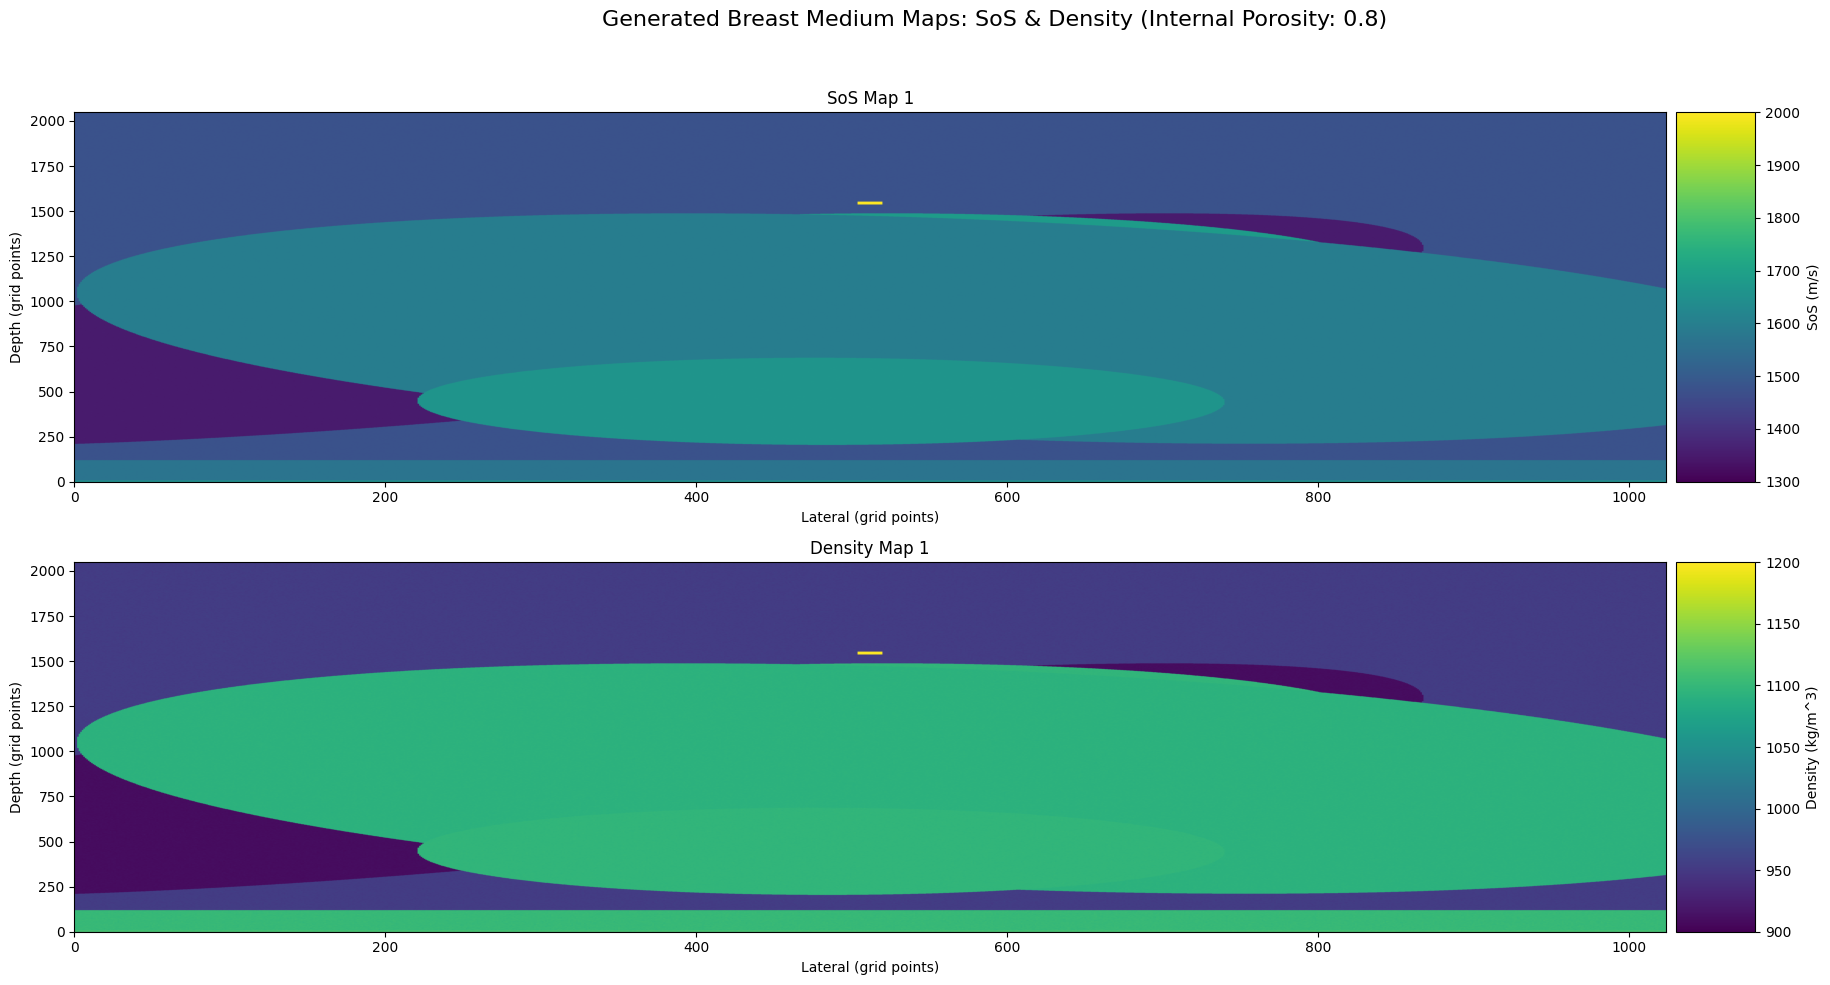

In [229]:
fig, axes = plt.subplots(2, 1, figsize=(20, 10))

# --- Plot SoS Map ---
im1 = axes[0].imshow(sos_maps[0].T[::-1, :], extent=[0, Nx, 0, Ny],
                     cmap='viridis', aspect='auto', vmin=1300, vmax=2000)
axes[0].set_title('SoS Map 1')
axes[0].set_xlabel('Lateral (grid points)')
axes[0].set_ylabel('Depth (grid points)')

divider1 = make_axes_locatable(axes[0])
cax1 = divider1.append_axes("right", size="5%", pad=0.1)
fig.colorbar(im1, cax=cax1, label='SoS (m/s)')

# --- Plot Density Map ---
im2 = axes[1].imshow(den_maps[0].T[::-1, :], extent=[0, Nx, 0, Ny],
                     cmap='viridis', aspect='auto', vmin=900, vmax=1200)
axes[1].set_title('Density Map 1')
axes[1].set_xlabel('Lateral (grid points)')
axes[1].set_ylabel('Depth (grid points)')

divider2 = make_axes_locatable(axes[1])
cax2 = divider2.append_axes("right", size="5%", pad=0.1)
fig.colorbar(im2, cax=cax2, label='Density (kg/m^3)')

plt.suptitle('Generated Breast Medium Maps: SoS & Density (Internal Porosity: 0.8)', fontsize=16)
plt.tight_layout(rect=[0, 0, 0.92, 0.95])
plt.savefig("case_1.png", dpi= 300 , bbox_inches = 'tight')


In [213]:
# # Assuming num_data is the number of maps generated
# fig, axes = plt.subplots(2, 1, figsize=(20, 10))

# for i in range(1):
#     # --- Plot SoS Map ---
#     # Fixed extent: [0, Nx, 0, Ny] ensures Depth 0
#     #  is at the top and Ny is at the bottom
#     im1 = axes[0, i].imshow(sos_maps[i].T[::-1 , :], extent=[0, Nx, 0, Ny], cmap='viridis', aspect='auto', vmin=1300, vmax=2000)
#     axes[0, i].set_title(f'SoS Map {i+1}')
#     axes[0, i].set_xlabel('Lateral (grid points)')
#     axes[0, i].set_ylabel('Depth (grid points)')

#     # Corrected colorbar logic to use num_data index
#     if i == num_data - 1:
#         divider1 = make_axes_locatable(axes[0, i])
#         cax1 = divider1.append_axes("right", size="5%", pad=0.1)
#         fig.colorbar(im1, cax=cax1, label='SoS (m/s)')

#     # --- Plot Density Map ---
#     im2 = axes[1, i].imshow(den_maps[i].T[::-1 , :], extent=[0, Nx, 0, Ny], cmap='viridis', aspect='auto', vmin=900, vmax=1200)
#     axes[1, i].set_title(f'Density Map {i+1}')
#     axes[1, i].set_xlabel('Lateral (grid points)')
#     axes[1, i].set_ylabel('Depth (grid points)')

#     # Corrected colorbar logic for density row
#     if i == num_data - 1:
#         divider2 = make_axes_locatable(axes[1, i])
#         cax2 = divider2.append_axes("right", size="5%", pad=0.1)
#         fig.colorbar(im2, cax=cax2, label='Density (kg/m^3)')
# # plt.suptitle('Generated Homogeneous Medium Maps: SoS & Density ', fontsize=16)
# plt.suptitle('Generated Breast Medium Maps: SoS & Density (Internal Porosity: 0.8)', fontsize=16)
# plt.tight_layout(rect=[0, 0, 0.92, 0.95])
# plt.show()

In [214]:
medium= []
for i in range(num_data):
    medium.append(kWaveMedium(sound_speed=sos_maps[i], density=den_maps[i]))

In [215]:
"""#defining the source and sensor (sonoghraphic setup) :
sensor_length = 30 #300 \mu m
pitch = 2 #30 \mu m
null_sider_areas = np.zeros((int(Nx/4), Ny), dtype=bool)
imaging_area = np.zeros((int(Nx/2) , Ny) , dtype=bool)
# Create repeating pattern: sensor_length x True + pitch x False = period 32
pattern_length = sensor_length + pitch
pattern = np.array([True]*sensor_length + [False]*pitch)

# Tile the pattern to cover the entire row
tiled_pattern = np.tile(pattern, Ny // pattern_length + 1)[:Ny]

# Apply pattern to the last row
imaging_area[:, -1] = tiled_pattern

#Generate the entire map
s_mask = np.vstack((null_sider_areas , imaging_area ,null_sider_areas))
#ploting the source pos in the map
plt.imshow(s_mask.T, cmap='gray')
plt.title('Source and Sensor Mask (Line Source at bottom Edge)')
plt.xlabel('Lateral (grid points)')
plt.ylabel('Depth (grid points)')
plt.show()

#defining the sensors :
sensor = kSensor(mask=s_mask, record=['p'])
"""

<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\m'
C:\Users\alira\AppData\Local\Temp\ipykernel_5524\2393963102.py:2: SyntaxWarning: invalid escape sequence '\m'
  sensor_length = 30 #300 \mu m


"#defining the source and sensor (sonoghraphic setup) :\nsensor_length = 30 #300 \\mu m\npitch = 2 #30 \\mu m\nnull_sider_areas = np.zeros((int(Nx/4), Ny), dtype=bool)\nimaging_area = np.zeros((int(Nx/2) , Ny) , dtype=bool)\n# Create repeating pattern: sensor_length x True + pitch x False = period 32\npattern_length = sensor_length + pitch\npattern = np.array([True]*sensor_length + [False]*pitch)\n\n# Tile the pattern to cover the entire row\ntiled_pattern = np.tile(pattern, Ny // pattern_length + 1)[:Ny]\n\n# Apply pattern to the last row\nimaging_area[:, -1] = tiled_pattern\n\n#Generate the entire map\ns_mask = np.vstack((null_sider_areas , imaging_area ,null_sider_areas))\n#ploting the source pos in the map\nplt.imshow(s_mask.T, cmap='gray')\nplt.title('Source and Sensor Mask (Line Source at bottom Edge)')\nplt.xlabel('Lateral (grid points)')\nplt.ylabel('Depth (grid points)')\nplt.show()\n\n#defining the sensors :\nsensor = kSensor(mask=s_mask, record=['p'])\n"

In [216]:
def microns2grid(length):
    dx = Decimal('10e-6')
    return int(Decimal(str(length)) * Decimal('1e-6') / dx)


sensor_length = 300 #300 \mu m

dx = Decimal('10e-6')
int(Decimal(str(sensor_length)) * Decimal('1e-6') / dx)


30

In [217]:
numbers_of_sensors = 32
sensor_length = 30 #300 \mu m
pitch = 2 #30 \mu m
pattern_length = sensor_length + pitch
pattern = np.array([True]*sensor_length + [False]*pitch)

# Tile the pattern to cover the entire row
imaging_area_last_row = np.tile(pattern, numbers_of_sensors)

imaging_area = np.zeros((int(len(imaging_area_last_row)) , Ny) , dtype=bool)
# imaging_area[:, -1] = imaging_area_last_row
imaging_area[:, 0] = imaging_area_last_row
sider_area = np.zeros((int((Nx-len(imaging_area_last_row))/2) , Ny) , dtype=bool)

s_mask = np.vstack((sider_area , imaging_area ,sider_area))
#defining the sensors :
sensor = kSensor(mask=s_mask, record=['p'])

In [218]:
Nx
imaging_area_last_row

array([ True,  True,  True, ...,  True, False, False], shape=(1024,))

### ploting the cropped map to check the source pos in the map

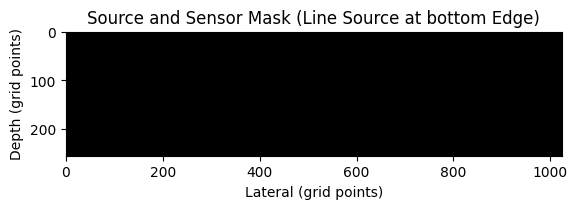

In [219]:
cropped_map = s_mask[Nx//2-Nx-len(imaging_area_last_row)//2:Nx//2+len(imaging_area_last_row)//2,Ny-len(imaging_area_last_row)//4:Ny]

#ploting the cropped map to check the source pos in the map
plt.imshow(cropped_map.T, cmap='gray')
plt.title('Source and Sensor Mask (Line Source at bottom Edge)')
plt.xlabel('Lateral (grid points)')
plt.ylabel('Depth (grid points)')
plt.show()

In [ ]:
# 1. Create the base pulse (Tone Burst)
source = kSource()
amplitude  = 1
num_cycles = 1
f0 = 5e6 # 5 MHz center frequency
t_pulse = np.arange(0, num_cycles / f0, grid.dt)
# Gaussian windowed sine wave
pulse_signal = amplitude * np.sin(2 * np.pi * f0 * t_pulse)# * np.exp(-((t_pulse - t_pulse[-1]/2)**2) / (2 * (t_pulse[-1]/6)**2))

# Pad with zeros to match simulation time
source_signal = np.zeros(grid.Nt)
source_signal[:len(pulse_signal)] = pulse_signal
# # Define focal point (e.g., 15mm deep in the center)
# x_focus = Nx*dx//2 + 15e-3
# y_focus = Ny*dy//2

# # Get coordinates of all active source elements
# element_idx = np.where(s_mask)
# x_coords = X[element_idx]
# y_coords = Y[element_idx]

# # Calculate distances to focus
# distances = np.sqrt((x_coords - x_focus)**2 + (y_coords - y_focus)**2)

# # Convert distance to time delays (relative to the furthest element)
# sound_speed = 1540 # [m/s]
# time_delays = (np.max(distances) - distances) / sound_speed
# delay_offsets = np.round(time_delays / grid.dt).astype(int)
s_mask = np.zeros((Nx , Ny ), dtype=bool)
s_mask[Nx//2 , Ny * 3//4] = 1
source.p_mask = s_mask.astype(float)
# source.p should have shape (num_source_elements, num_time_steps)
num_source_elements = int(np.sum(s_mask))
source.p = np.tile(source_signal.reshape(1, -1), (num_source_elements, 1))  # set the source pressure signal


# #Create the Apodization Weights (Hann Window)
# # We normalize the position of elements from 0 to 1 across the width
# y_min, y_max = np.min(y_coords), np.max(y_coords)
# normalized_y = (y_coords - y_min) / (y_max - y_min)

# # Calculate Hann weights: 0.5 * (1 - cos(2 * pi * n))
# apodization_weights = 0.5 * (1 - np.cos(2 * np.pi * normalized_y))

# Apply weights to source.p
# Assuming you already have your source.p matrix (num_elements, num_time_steps)
# We multiply each row (element) by its corresponding weight
#source.p = source.p * apodization_weights.reshape(-1, 1)

In [221]:
np.sum(s_mask)

np.int64(1)

In [222]:
from kwave.options.simulation_options import SimulationOptions
from kwave.options.simulation_execution_options import SimulationExecutionOptions
sim_options = SimulationOptions(pml_inside=False, save_to_disk=True)
exec_options = SimulationExecutionOptions(is_gpu_simulation=True,backend = 'CUDA')
# exec_options = SimulationExecutionOptions(is_gpu_simulation=False)
sensor_data = kspaceFirstOrder2D(grid, source, sensor, medium[1], simulation_options=sim_options, execution_options=exec_options)

<@beartype(kwave.kspaceFirstOrder2D.kspaceFirstOrder2D) at 0x24be7276980>:130: FutureWarning: kspaceFirstOrder2D is deprecated. Use kspaceFirstOrder() from kwave.kspaceFirstOrder instead. See kwave.compat.options_to_kwargs() for migrating options.
c:\Users\alira\Desktop\Alirad\kwave-Breast-Tissue-Modeling-main\ac\Lib\site-packages\kwave\options\simulation_execution_options.py:155: UserWarning: Custom binary name set. Ignoring `is_gpu_simulation` state.
  warnings.warn("Custom binary name set. Ignoring `is_gpu_simulation` state.")


+---------------------------------------------------------------+
|                  kspaceFirstOrder-CUDA v1.3                   |
+---------------------------------------------------------------+
| Reading simulation configuration:                        Done |
| Selected GPU device id:                                     0 |
| GPU device name:                      NVIDIA GeForce RTX 4080 |
| Number of CPU threads:                                      1 |
| Processor name:         13th Gen Intel(R) Core(TM) i7-13700KF |
+---------------------------------------------------------------+
|                      Simulation details                       |
+---------------------------------------------------------------+
| Domain dimensions:                                1064 x 2088 |
| Medium type:                                               2D |
| Simulation time steps:                                   9241 |
+---------------------------------------------------------------+
|         

In [223]:
from pathlib import Path

rf_data_dir = Path("./")
sensor_elements_data = sensor_data['p']

# Determine the number of complete channels we can form
num_channels = sensor_elements_data.shape[1] // sensor_length
valid_cols = num_channels * sensor_length

# Slice to drop any trailing columns that don't make a full channel
trimmed_data = sensor_elements_data[:, :valid_cols]

# Reshape and sum along the sensor_length dimension, then average
RF_data = trimmed_data.reshape(trimmed_data.shape[0], -1, sensor_length).sum(axis=2) / sensor_length

np.save(rf_data_dir/"homo_reflect_1.npy", arr =RF_data )

In [15]:
sensor_length = 30
sensor_elements_data = sensor_data['p']

# 1. Determine the number of complete channels we can form
num_channels = sensor_elements_data.shape[1] // sensor_length
valid_cols = num_channels * sensor_length

# 2. Slice to drop any trailing columns that don't make a full channel
trimmed_data = sensor_elements_data[:, :valid_cols]

# 3. Reshape and sum along the sensor_length dimension, then average
RF_data = trimmed_data.reshape(trimmed_data.shape[0], -1, sensor_length).sum(axis=2) / sensor_length

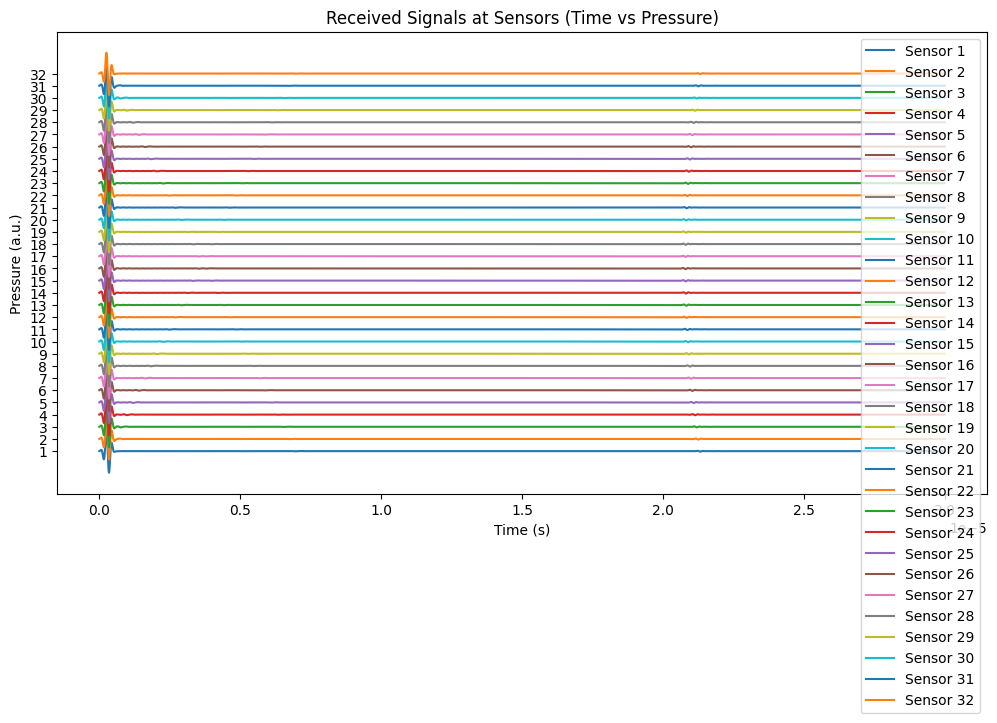

In [125]:
# sensor_data['p'][time,sensor_element] gives the pressure at a specific time and sensor element.
#ploting the received signals at the sensors in parallel channels :
"""plt.figure(figsize=(12, 6))
for i in range(RF_data.shape[1]):
    plt.plot(grid.t_array.flatten(), RF_data[:, i] + i*0.5, label=f'Sensor {i+1}')  # Offset each signal for visibility
plt.title('Received Signals at Sensors (Time vs Pressure)')
plt.xlabel('Time (s)')
plt.ylabel('Pressure (a.u.)')
plt.yticks(np.arange(0, RF_data.shape[1]*0.5, 0.5), [f'Sensor {i+1}' for i in range(RF_data.shape[1])])
plt.legend(loc='upper right')
plt.show()"""
plt.figure(figsize=(12, 6))
for i in range(RF_data.shape[1]):
    plt.plot(grid.t_array.flatten(), RF_data[:, i] + i*0.5,  label=f'Sensor {i+1}')  # Offset each signal for visibility
plt.title('Received Signals at Sensors (Time vs Pressure)')
plt.xlabel('Time (s)')
plt.ylabel('Pressure (a.u.)')
plt.yticks(np.arange(0, RF_data.shape[1]*0.5, 0.5), [i+1 for i in range(RF_data.shape[1])])
plt.legend(loc='upper right')
plt.show()